<a href="https://colab.research.google.com/github/Fittx/Machine-Learning---CCMACLRL/blob/main/ML-GDG-Exercises/%5B04%5D_Data_Augmentation_and_Model_Deployment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4. Data Augmentation and Model Deployment

---
### ✏️ How this notebook works
Most coding cells in this notebook come in a pair:

1. **📘 Worked Example:** a small, working demo of the *pattern* you'll need, in a different scenario from the real task. Run it first and read the comments.
2. **✏️ Fill-in-the-blank cell:** wherever you see a blank (`_____`), write the missing code yourself. The example shows the pattern, but you'll need to work out the exact answer using the section's explanation and the `Hint` comments.

Cells with a **✅ Check** at the bottom will tell you whether your answers are right. Run the cells in order from top to bottom. (Setup, data-download, training-loop and display cells are already complete; just run them.)

In the previous module you trained a Convolutional Neural Network (CNN) from scratch. You likely noticed that training accuracy climbed faster than validation accuracy — a classic sign of **overfitting**. The model was memorizing the training images rather than learning generalizable features.

In this module, we tackle overfitting from two angles:

1. **Data Quality** — understanding what makes a dataset "good enough" to train on, and inspecting our dataset for common issues.
2. **Data Augmentation** — programmatically increasing the size and variety of our training data using `TorchVision Transforms`, so the model learns to ignore irrelevant variations (angle, lighting, flips, crops) and focus on what actually matters.

We will then close the loop on the deep learning workflow by:

3. **Saving and loading models** — so a trained model can be reused without retraining.
4. **Running inference** — using our saved model to classify brand-new, unseen images.

We'll be working with the **[Sea Animals Image Dataset](https://www.kaggle.com/datasets/vencerlanz09/sea-animals-image-dataste)** from Kaggle, which contains images across dozens of marine species (fish, sharks, turtles, jellyfish, crabs, and more). This gives us a fun, real-world multi-class image classification problem distinct from the ASL dataset used earlier.

## 4.1 Objectives

By the end of this module, you will be able to:

* Explain what data quality means in the context of deep learning and identify common dataset issues
* Apply `TorchVision Transforms` (v2) to augment an image dataset
* Train a CNN on augmented data and compare it against a non-augmented baseline
* Save a trained PyTorch model to disk
* Load a saved model and use it to run inference on new, unseen images

## 4.2 Environment Setup

As with previous modules, we'll mount Google Drive (where the dataset lives for this course) and import the libraries we need.

In [1]:
# 1. Mount your Google Drive to the Colab environment
from google.colab import drive
drive.mount('/content/drive')

# 2. Change the active directory to your exact course folder
%mkdir "/content/drive/MyDrive/Colab Notebooks"
%cd "/content/drive/MyDrive/Colab Notebooks"
%mkdir "/content/drive/MyDrive/Colab Notebooks/FAIDLP Bootcamp"
%cd "/content/drive/MyDrive/Colab Notebooks/FAIDLP Bootcamp"

# 3. Force Python to look in this directory for local helper scripts
import sys
sys.path.append("/content/drive/MyDrive/Colab Notebooks/FAIDLP Bootcamp")

import os
print(os.listdir("/content/drive/MyDrive/Colab Notebooks/FAIDLP Bootcamp"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
mkdir: cannot create directory ‘/content/drive/MyDrive/Colab Notebooks’: File exists
/content/drive/MyDrive/Colab Notebooks
mkdir: cannot create directory ‘/content/drive/MyDrive/Colab Notebooks/FAIDLP Bootcamp’: File exists
/content/drive/MyDrive/Colab Notebooks/FAIDLP Bootcamp
[]


In [2]:
# Upgrade sympy to a compatible version, and reinstall torchvision/torch to resolve the compatibility error
!pip install --upgrade "sympy==1.13.3" torchvision torch

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms.v2 as transforms
import torchvision.io as tv_io

import glob
import os
import json
import matplotlib.pyplot as plt

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Is CUDA available?:", torch.cuda.is_available())

Is CUDA available?: True


## 4.3 The Dataset: Sea Animals

`We'll use the **[Sea Animals Image Dataset](https://www.kaggle.com/datasets/vencerlanz09/sea-animals-image-dataste)**, downloaded via `kagglehub` below. It contains folders of images, one folder per species — a standard `ImageFolder`-style layout:

```
sea_animals/
├── Clams/
├── Corals/
├── Crabs/
├── Dolphin/
├── Eel/
├── Jelly Fish/
├── Octopus/
├── Sea Rays/
├── Sharks/
├── Turtle_Tortoise/
└── ... (more species)
```

Run the cell below to download the dataset directly into your Colab environment.

In [3]:
# Download the Sea Animals dataset from Kaggle
!pip install -q kagglehub

import kagglehub

DATA_PATH = kagglehub.dataset_download("vencerlanz09/sea-animals-image-dataste")
print("Dataset downloaded to:", DATA_PATH)

Using Colab cache for faster access to the 'sea-animals-image-dataste' dataset.
Dataset downloaded to: /kaggle/input/sea-animals-image-dataste


In [4]:
# Peek at the class folders available in the dataset
class_names = sorted(os.listdir(DATA_PATH))
print(f"Found {len(class_names)} classes:")
print(class_names)

Found 23 classes:
['Clams', 'Corals', 'Crabs', 'Dolphin', 'Eel', 'Fish', 'Jelly Fish', 'Lobster', 'Nudibranchs', 'Octopus', 'Otter', 'Penguin', 'Puffers', 'Sea Rays', 'Sea Urchins', 'Seahorse', 'Seal', 'Sharks', 'Shrimp', 'Squid', 'Starfish', 'Turtle_Tortoise', 'Whale']


### 4.3.1 Data Quality

Before we train anything, it's worth pausing on **data quality**. A model is only as good as the data it learns from — the classic "garbage in, garbage out" problem. When inspecting a new dataset, we're generally looking out for:

* **Class imbalance** — do some species have far more images than others? An imbalanced dataset can bias the model toward the majority classes.
* **Corrupted or unreadable files** — images that fail to open, or are 0 bytes.
* **Mislabeled images** — images placed in the wrong class folder.
* **Duplicate images** — the same (or near-identical) image appearing multiple times, which can inflate apparent accuracy.
* **Resolution and aspect ratio variance** — wildly different image sizes that will need consistent resizing.

Let's write a quick audit of our sea animals dataset to check for class imbalance and corrupted files.

In [5]:
# 📘 WORKED EXAMPLE (run me first!): auditing a folder of files
import glob, json, os, tempfile

# Build a throwaway folder with a few files so we have something to inspect
demo_folder = tempfile.mkdtemp()
for name in ["a.txt", "b.txt", "c.txt", "notes.log"]:
    with open(os.path.join(demo_folder, name), "w") as f:
        f.write('{"ok": true}' if name != "c.txt" else "{ broken")

# glob finds every file whose name matches a pattern. In a pattern, "*" stands for "anything at all".
text_files = glob.glob(os.path.join(demo_folder, "*.txt"))
print("How many .txt files?", sum(1 for _ in text_files))

# Spot-check each file. If opening it as JSON fails, we remember the file as "broken".
broken_files = []
for path in text_files:
    try:
        with open(path) as f:
            json.load(f)          # raises an error when the content is not valid JSON
    except Exception:
        broken_files.append(os.path.basename(path))
print("Broken files:", broken_files)

How many .txt files? 3
Broken files: ['c.txt']


In [6]:
from PIL import Image

class_counts = {}
corrupted_files = []

for cls in class_names:
    cls_folder = os.path.join(DATA_PATH, cls)
    if not os.path.isdir(cls_folder):
        continue
    # ✏️ (1/3) Use a pattern that matches EVERY file inside the class folder
    files = glob.glob(os.path.join(cls_folder, "*"))
    # ✏️ (2/3) Count how many files this class has
    class_counts[cls] =len(files)

    # Spot-check a handful of files per class for corruption
    for f in files[:20]:
        try:
            with Image.open(f) as img:
                img.verify()     # ✏️ (3/3) PIL's built-in integrity check: it raises an error if the image is damaged
        except Exception:
            corrupted_files.append(f)

print("Class counts (sample):")
for cls, count in list(class_counts.items())[:10]:
    print(f"  {cls}: {count} images")

print(f"\nCorrupted/unreadable files found in spot-check: {len(corrupted_files)}")

# ✅ Check: run this to see if your answers are right
assert len(class_counts) > 0 and all(isinstance(v, int) and v > 0 for v in class_counts.values()), "Every class should have a positive image count"
print("Correct!")

Class counts (sample):
  Clams: 497 images
  Corals: 500 images
  Crabs: 499 images
  Dolphin: 782 images
  Eel: 497 images
  Fish: 494 images
  Jelly Fish: 845 images
  Lobster: 499 images
  Nudibranchs: 500 images
  Octopus: 562 images

Corrupted/unreadable files found in spot-check: 0
Correct!


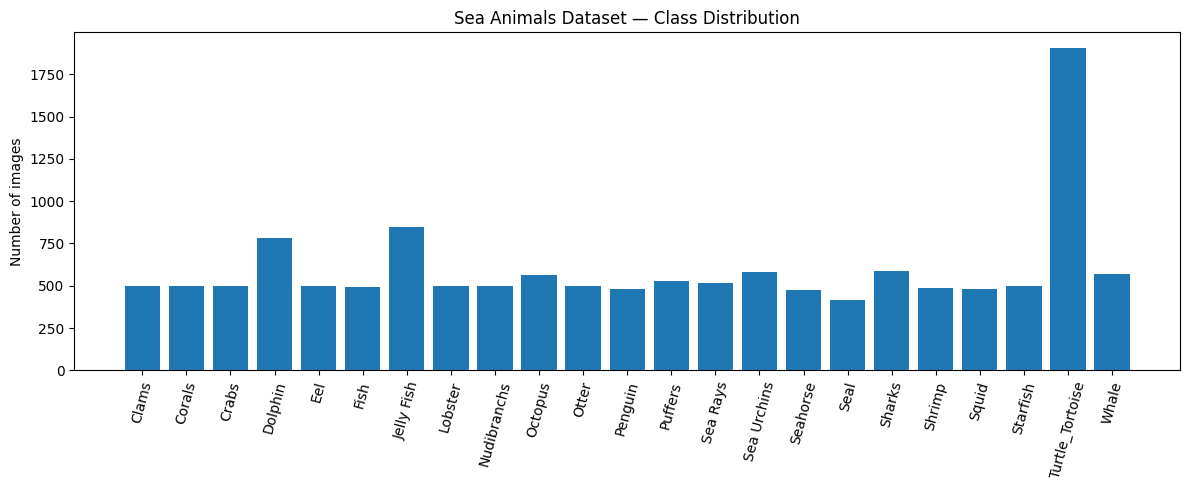

In [7]:
# Visualize class balance
plt.figure(figsize=(12, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=75)
plt.ylabel("Number of images")
plt.title("Sea Animals Dataset — Class Distribution")
plt.tight_layout()
plt.show()

**Discussion:** Notice that some classes have noticeably more images than others. In a production project, this is where you'd consider strategies like collecting more data for underrepresented classes, oversampling, class-weighted loss functions, or — as we'll do next — **augmentation**, which helps every class "stretch" further by generating variations of the images we already have.

## 4.4 Preparing the Dataset and DataLoaders

We'll build a custom `Dataset` class that reads images from our class folders, resizes them to a consistent size, and returns `(image_tensor, label)` pairs — the same pattern you used with the ASL dataset.

In [8]:
# 📘 WORKED EXAMPLE (run me first!): a Dataset that remembers (item, number-label) pairs
import torch
from torch.utils.data import Dataset

class DemoWordDataset(Dataset):
    def __init__(self, folders):
        self.samples = []
        topic_names = list(folders.keys())
        for topic_id in range(len(topic_names)):                 # topic_id is the NUMBER we give each folder
            for word in folders[topic_names[topic_id]]:
                self.samples.append((word, topic_id))            # store (item, number), not (item, name)

    def __getitem__(self, position):
        word, topic_id = self.samples[position]                  # look up one stored pair
        return word.upper(), topic_id

    def __len__(self):
        return len(self.samples)

demo_data = DemoWordDataset({"fruit": ["apple", "pear"], "tools": ["saw", "drill", "axe"]})
print("Size:", len(demo_data))
print("Item 0:", demo_data[0])
print("Item 3:", demo_data[3])

# Images are resized with transforms.Resize((height, width)). Here is a fake 3-channel image being resized:
import torchvision.transforms.v2 as transforms
demo_resize = transforms.Resize((16, 24))
print("Resized fake image:", demo_resize(torch.rand(3, 50, 60)).shape)   # (channels, 16, 24)

Size: 5
Item 0: ('APPLE', 0)
Item 3: ('DRILL', 1)
Resized fake image: torch.Size([3, 16, 24])


In [9]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_CHS = 3
N_CLASSES = len(class_names)

pre_trans = transforms.Compose([
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Resize((IMG_HEIGHT, IMG_WIDTH)),   # ✏️ (1/4) every image must end up the same size
])

class SeaAnimalsDataset(Dataset):
    def __init__(self, root_dir, class_names, transform=None):
        self.transform = transform
        self.class_names = class_names
        self.samples = []
        # ✏️ (2/4) We want BOTH a number (label) and a name (cls) for each folder
        for label, cls in enumerate(class_names):
            cls_folder = os.path.join(root_dir, cls)
            for filepath in glob.glob(os.path.join(cls_folder, "*")):
                self.samples.append((filepath, label))   # ✏️ (3/4) store the number label

    def __getitem__(self, idx):
        filepath, label = self.samples[idx]   # ✏️ (4/4) fetch the stored pair at this position
        img = tv_io.read_image(filepath, tv_io.ImageReadMode.RGB)
        img = pre_trans(img)
        if self.transform:
            img = self.transform(img)
        return img.to(device), torch.tensor(label).to(device)

    def __len__(self):
        return len(self.samples)

# ✅ Check: run this to see if your answers are right
fake_photo = torch.randint(0, 256, (3, 50, 60), dtype=torch.uint8)
assert pre_trans(fake_photo).shape == (3, 224, 224), "Every image should be resized to 224x224"
print("Correct!")

Correct!


## 4.5 Data Augmentation with TorchVision Transforms

Now for the main event. `torchvision.transforms.v2` gives us a rich toolkit of image transformations we can chain together with `transforms.Compose`. Applied **only to the training set**, these transforms generate a new random variation of each image every epoch — effectively giving the model a much larger, more varied training set without collecting a single new photo.

Some transforms particularly useful for underwater / sea-animal photography:

| Transform | Why it helps here |
|---|---|
| `RandomHorizontalFlip` | Animals can face either direction |
| `RandomRotation` | Camera angle varies underwater |
| `ColorJitter` (brightness/contrast) | Water depth and lighting conditions vary a lot |
| `RandomResizedCrop` | Animals appear at different distances/scales |
| `GaussianBlur` | Simulates murky water or motion blur |

Let's define our augmentation pipeline.

In [10]:
# 📘 WORKED EXAMPLE (run me first!): augment, split, and batch
import torch
import torchvision.transforms.v2 as transforms
from torch.utils.data import DataLoader, random_split

# 1) Chain augmentations with Compose. The pipeline is called like a function and is random every time.
demo_pipeline = transforms.Compose([
    transforms.RandomVerticalFlip(p=0.5),                      # p = chance of flipping on any given call
    transforms.RandomGrayscale(p=0.3),
    transforms.RandomAffine(degrees=20, translate=(0.1, 0.1)),
])
demo_img = torch.rand(3, 32, 32)
for attempt in range(3):
    demo_out = demo_pipeline(demo_img)
    print("Same shape?", demo_out.shape == demo_img.shape, "| Identical pixels?", torch.equal(demo_out, demo_img))

# 2) Split ONE dataset into two parts by giving the sizes you want (they must add up to the total)
demo_all = torch.arange(10)
demo_part_a, demo_part_b = random_split(demo_all, [7, 3])
print("Sizes:", len(demo_part_a), len(demo_part_b))

# 3) Batching: shuffle=True reorders the samples every epoch, shuffle=False keeps the original order
for demo_flag in (False, True):
    demo_loader = DataLoader(demo_all, batch_size=5, shuffle=demo_flag)
    print(f"shuffle={demo_flag}:", [b.tolist() for b in demo_loader], [b.tolist() for b in demo_loader])

Same shape? True | Identical pixels? False
Same shape? True | Identical pixels? False
Same shape? True | Identical pixels? False
Sizes: 7 3
shuffle=False: [[0, 1, 2, 3, 4], [5, 6, 7, 8, 9]] [[0, 1, 2, 3, 4], [5, 6, 7, 8, 9]]
shuffle=True: [[1, 7, 5, 8, 3], [9, 6, 2, 0, 4]] [[8, 3, 9, 6, 1], [4, 5, 2, 0, 7]]


In [11]:
train_path = os.path.join(DATA_PATH, "train")
valid_path = os.path.join(DATA_PATH, "valid")

n=32

# ✏️ YOUR TURN (1/4): Build the augmentation pipeline from the table above. Pick the matching transform for each line.
random_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),      # animals can face either direction (50% of the time)
    transforms.RandomRotation(15),               # camera angle varies: rotate by up to 15 degrees
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),   # lighting varies
    transforms.RandomResizedCrop((IMG_HEIGHT, IMG_WIDTH), scale=(0.7, 1.0)),  # animals appear at different distances
    transforms.GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 1.5)),
])

# ✏️ (2/4) Pass the pipeline you just built to the dataset
full_dataset = SeaAnimalsDataset(DATA_PATH, class_names, transform=random_transforms)
print(f"Total Images: {len(full_dataset)}")

# ✏️ (3/4) 80% of the images for training, the rest for validation, split at random
train_len = int(0.8 * len(full_dataset))
valid_len = len(full_dataset) - train_len
train_data, valid_data = torch.utils.data.random_split(full_dataset, [train_len, valid_len])
print(f"Training Images: {len(train_data)} | Validation Images: {len(valid_data)}")

# ✏️ (4/4) The model learns from the training loader, so reshuffle it every epoch
train_loader = DataLoader(train_data, batch_size=n, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=n, shuffle=True)

# ✅ Check: run this to see if your answers are right
assert len(random_transforms.transforms) == 5, "The pipeline should have 5 transforms"
assert full_dataset.transform is random_transforms, "The dataset should use random_transforms"
assert len(train_data) + len(valid_data) == len(full_dataset) and abs(len(train_data) / len(full_dataset) - 0.8) < 0.01, "Use an 80/20 split"
assert train_loader.sampler.__class__.__name__ == "RandomSampler", "The training loader should shuffle"
print("Correct!")

Total Images: 13711
Training Images: 10968 | Validation Images: 2743
Correct!


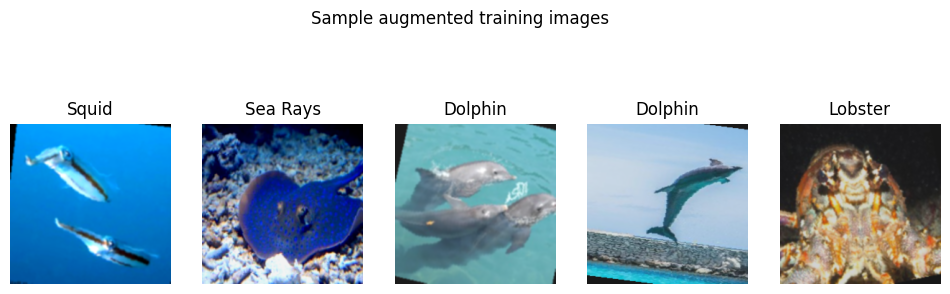

In [12]:
# Visualize a few augmented samples from the same image
image_batch, label_batch = next(iter(train_loader))

plt.figure(figsize=(12, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(image_batch[i].permute(1, 2, 0).cpu())
    plt.title(class_names[label_batch[i]])
    plt.axis("off")
plt.suptitle("Sample augmented training images")
plt.show()

## 4.6 Building and Training the Model

We'll reuse a compact CNN architecture similar to the one from Module 5, adapted for 3-channel, 224x224 sea animal images.

In [13]:
# 📘 WORKED EXAMPLE (run me first!): a conv block, and sizing the final Linear layer
import torch
import torch.nn as nn

class DemoBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),       # normalizes the channels the conv layer just produced
            nn.LeakyReLU(),
            nn.AvgPool2d(2),              # every block halves the height and width
        )

    def forward(self, x):
        return self.layers(x)

# Input: 1 channel, 16x16.  Output: 5 categories.
demo_net = nn.Sequential(
    DemoBlock(1, 4),                      # 16x16 -> 8x8   (4 channels)
    DemoBlock(4, 8),                      # 8x8   -> 4x4   (8 channels): this block's input = previous block's output
    nn.Flatten(),
    nn.Linear(8 * (16 // 4) * (16 // 4), 5),   # channels * height * width left after all the halving
)
print(demo_net(torch.randn(2, 1, 16, 16)).shape)   # (2, 5)

torch.Size([2, 5])


In [14]:
class MyConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_p=0.2):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(out_ch),                        # ✏️ (1/7) normalize the channels the conv just produced
            nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1),   # ✏️ (2/7) this conv receives the previous conv's output
            nn.BatchNorm2d(out_ch),
            nn.ReLU(),
            nn.MaxPool2d(2, stride=2),                      # ✏️ (3/7) a 2x2 window
            nn.Dropout(dropout_p),                          # ✏️ (4/7) use the block's dropout setting
        )

    def forward(self, x):
        return self.block(x)


base_model = nn.Sequential(
    MyConvBlock(IMG_CHS, 32),
    MyConvBlock(32, 64),             # ✏️ (5/7) input channels = the previous block's output channels
    MyConvBlock(64, 128),
    nn.Flatten(),
    # ✏️ (6/7) Each block halves the height and width. After 3 blocks, the image is 2^3 = 8 times smaller.
    nn.Linear(128 * (IMG_HEIGHT // 8) * (IMG_WIDTH // 8), 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, N_CLASSES),       # ✏️ (7/7) one score per species
)

model = torch.compile(base_model.to(device))
print(model)

# ✅ Check: run this to see if your answers are right
base_model.eval()
with torch.no_grad():
    test_scores = base_model(torch.randn(2, IMG_CHS, IMG_HEIGHT, IMG_WIDTH).to(device))
assert test_scores.shape == (2, N_CLASSES), "2 images in should give 2 rows of N_CLASSES scores"
print("Correct!")

OptimizedModule(
  (_orig_mod): Sequential(
    (0): MyConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU()
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout(p=0.2, inplace=False)
      )
    )
    (1): MyConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(6

In [15]:
# 📘 WORKED EXAMPLE (run me first!): argmax, training mode vs. prediction mode
import torch
import torch.nn as nn

# 1) argmax: which axis ("dim") do we search along?
demo_scores = torch.tensor([[0.1, 2.5, 0.3],     # image 1: scores for 3 classes
                            [1.2, 0.4, 0.9]])    # image 2
print("Best class per ROW  :", demo_scores.argmax(dim=1).tolist())   # one answer per image
print("Best image per COLUMN:", demo_scores.argmax(dim=0).tolist())  # not what we want for classification

# 2) Some layers (like Dropout) behave differently in training vs. prediction.
demo_model = nn.Sequential(nn.Linear(4, 4), nn.Dropout(0.5))
demo_input = torch.ones(1, 4)
demo_model.eval()                                   # prediction mode: Dropout is switched off
print("Prediction mode, two runs match? ", torch.equal(demo_model(demo_input), demo_model(demo_input)))
print("Is it training?", demo_model.training)       # a flag that records the current mode

# 3) An optimizer needs a learning rate (lr): the size of each update step
import torch.optim as optim
demo_opt = optim.Adam(demo_model.parameters(), lr=0.01)
print("Step size:", demo_opt.param_groups[0]["lr"])

# 4) During validation we do not need gradients, so we skip tracking them
with torch.inference_mode():
    demo_out = demo_model(demo_input)
print("Gradient tracking on?", demo_out.requires_grad)

Best class per ROW  : [1, 0]
Best image per COLUMN: [1, 0, 1]
Prediction mode, two runs match?  True
Is it training? False
Step size: 0.01
Gradient tracking on? False


In [19]:
# ✏️ Loss function for multi-class classification
loss_function = nn.CrossEntropyLoss()
# ✏️ Adam optimizer with a learning rate of 0.001 (the size of each update step)
optimizer = Adam(model.parameters(), lr=0.001)

def get_batch_accuracy(output, y):
    # ✏️ (2/4) We want the best class for EACH image (see the worked example): which dim?
    pred = output.argmax(dim=1, keepdim=True)
    correct = pred.eq(y.view_as(pred)).sum().item()
    return correct


def train():
    total_loss = 0
    total_correct = 0
    model.train()          # ✏️ (3/4) switch to TRAINING mode (the opposite of eval)
    for x, y in train_loader:
        output = model(x)
        optimizer.zero_grad()
        batch_loss = loss_function(output, y)
        batch_loss.backward()  # ✏️ (4/4) compute the gradients
        optimizer.step()

        total_loss += batch_loss.item()
        total_correct += get_batch_accuracy(output, y)

    avg_loss = total_loss / len(train_loader)
    avg_accuracy = total_correct / len(train_data)
    print(f"Train - Loss: {avg_loss:.4f} Accuracy: {avg_accuracy:.4f}")


def validate():
    total_loss = 0
    total_correct = 0
    model.eval()
    # ✏️ Validation should not track gradients (the worked example showed one way; there is also a classic context manager)
    with torch.no_grad():
        for x, y in valid_loader:
            output = model(x)
            batch_loss = loss_function(output, y)

            total_loss += batch_loss.item()
            total_correct += get_batch_accuracy(output, y)
    avg_loss = total_loss / len(valid_loader)
    avg_accuracy = total_correct / len(valid_data)

    print(f"Valid - Loss: {avg_loss:.4f} Accuracy: {avg_accuracy:.4f}")

# ✅ Check: run this to see if your answers are right
_scores = torch.tensor([[0.1, 0.9], [0.8, 0.2]])
_truth = torch.tensor([1, 0])
assert isinstance(loss_function, nn.CrossEntropyLoss), "Use CrossEntropyLoss"
assert optimizer.param_groups[0]["lr"] == 0.001, "Use a learning rate of 0.001"
print("Correct!")

Correct!


In [20]:
epochs = 5

for epoch in range(epochs):
    print(f"Epoch: {epoch}")
    train()
    validate()

Epoch: 0


/usr/local/lib/python3.13/dist-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


Train - Loss: 4.0739 Accuracy: 0.0982
Valid - Loss: 3.1084 Accuracy: 0.1345
Epoch: 1
Train - Loss: 3.0943 Accuracy: 0.1399
Valid - Loss: 3.0869 Accuracy: 0.1345
Epoch: 2
Train - Loss: 3.0750 Accuracy: 0.1399
Valid - Loss: 3.0735 Accuracy: 0.1345
Epoch: 3
Train - Loss: 3.0621 Accuracy: 0.1399
Valid - Loss: 3.0661 Accuracy: 0.1345
Epoch: 4
Train - Loss: 3.0555 Accuracy: 0.1399
Valid - Loss: 3.0630 Accuracy: 0.1345


**Discussion:** With augmentation, expect training accuracy to rise more slowly than in Module 5 — the model is seeing a harder, more varied version of the data every epoch. In exchange, validation accuracy should be higher and more stable, since the model has learned features that generalize rather than memorized specific pixels.

## 4.7 Saving the Model

Once we're happy with a trained model, we save it to disk so it can be reused later without retraining. PyTorch offers [multiple ways](https://pytorch.org/tutorials/beginner/saving_loading_models.html) to do this. We'll use `torch.save` to save the full model object, along with a small JSON file mapping class indices to species names — we'll need that mapping later at inference time.

In [21]:
# 📘 WORKED EXAMPLE (run me first!): saving a model and a label list with different tools
import pickle, json, os, tempfile
import torch.nn as nn

demo_dir = tempfile.mkdtemp()
demo_model = nn.Linear(3, 2)

# A binary file ("wb" = write bytes) is needed for a model object
model_file = os.path.join(demo_dir, "demo_model.pkl")
with open(model_file, "wb") as f:
    pickle.dump(demo_model, f)           # Python's general-purpose "save this object" function

# A plain-text file ("w" = write text) is fine for a simple list of names
labels_file = os.path.join(demo_dir, "demo_labels.json")
with open(labels_file, "w") as f:
    f.write(json.dumps(["rock", "paper", "scissors"]))   # dumps = turns the list into a text string

print("Files created:", sorted(os.listdir(demo_dir)))

Files created: ['demo_labels.json', 'demo_model.pkl']


In [23]:
# ✏️ YOUR TURN
# Save the trained model. PyTorch has its own function for writing a model to disk.
torch.save(base_model, "sea_animals_model.pth")

# Save the class index -> class name mapping for use during inference
# ✏️ Open the file for WRITING text, then use the json function that writes a Python object straight into a file object
with open("sea_animals_classes.json", "w") as f:
    json.dump(class_names, f)

print("Model and class mapping saved.")

# ✅ Check: run this to see if your answers are right
assert os.path.exists("sea_animals_model.pth") and os.path.exists("sea_animals_classes.json"), "Both files should exist now"
print("Correct!")

Model and class mapping saved.
Correct!


## 4.8 Loading the Model and Running Inference

Now let's simulate deployment: load the saved model fresh (as if in a new session), and use it to classify a brand-new image the model has never seen.

In [24]:
# 📘 WORKED EXAMPLE (run me first!): loading things back
import pickle, json, os, tempfile
import torch.nn as nn

# (set-up: create the files we are about to load)
demo_dir = tempfile.mkdtemp()
with open(os.path.join(demo_dir, "m.pkl"), "wb") as f:
    pickle.dump(nn.Linear(3, 2), f)
with open(os.path.join(demo_dir, "labels.json"), "w") as f:
    f.write(json.dumps(["rock", "paper", "scissors"]))

# Loading mirrors saving: open in the matching mode ("rb" = read bytes), then call the matching "load"
with open(os.path.join(demo_dir, "m.pkl"), "rb") as f:
    demo_loaded = pickle.load(f)
with open(os.path.join(demo_dir, "labels.json")) as f:
    demo_names = json.loads(f.read())      # loads = from a text string back into a Python list

print(demo_loaded)
print(demo_names)

Linear(in_features=3, out_features=2, bias=True)
['rock', 'paper', 'scissors']


In [27]:
# ✏️ YOUR TURN
# Load the saved model. (weights_only=False is needed because we saved the whole model object)
loaded_model = torch.load("sea_animals_model.pth", weights_only=False)
loaded_model.eval()
loaded_model.to(device)

# Load the class mapping (the json function that reads straight from a file object)
with open("sea_animals_classes.json") as f:
    loaded_class_names = json.load(f)

print("Model loaded. Ready for inference on", len(loaded_class_names), "classes.")

# ✅ Check: run this to see if your answers are right
assert isinstance(loaded_model, nn.Module), "torch.load should give back a model"
assert loaded_class_names == class_names, "The loaded class names should match the saved ones"
print("Correct!")

Model loaded. Ready for inference on 23 classes.
Correct!


In [28]:
# 📘 WORKED EXAMPLE (run me first!): from a single image to a predicted name
import torch
import torch.nn as nn

demo_names = ["red", "green", "blue"]
demo_classifier = nn.Sequential(nn.Flatten(), nn.Linear(3 * 4 * 4, 3))
demo_classifier.eval()

demo_image = torch.rand(3, 4, 4)       # ONE image: (channels, height, width)
demo_batch = demo_image[None]          # models expect a BATCH, so add an axis of size 1 at the front
print("Single image:", tuple(demo_image.shape), "-> batch of one:", tuple(demo_batch.shape))

with torch.no_grad():
    demo_scores = demo_classifier(demo_batch)            # shape (1, 3): one row of 3 scores
demo_best = demo_scores.argmax(dim=-1).item()            # the position of the best score, as a plain number
print("Predicted position:", demo_best, "-> name:", demo_names[demo_best])   # use the position to look up the name

Single image: (3, 4, 4) -> batch of one: (1, 3, 4, 4)
Predicted position: 1 -> name: green


In [30]:
def load_and_process_image(filepath):
    image = tv_io.read_image(filepath, tv_io.ImageReadMode.RGB)
    image = pre_trans(image)
    image = image.unsqueeze(0)  # ✏️ add a batch dimension at the front
    return image.to(device)


def predict_species(filepath):
    image = load_and_process_image(filepath)
    output = loaded_model(image)
    predicted_idx = output.argmax(dim=1).item()          # ✏️ the output has shape (1, N_CLASSES): search across the classes
    predicted_class = loaded_class_names[predicted_idx]   # ✏️ use the position to look up the species name

    plt.imshow(image[0].permute(1, 2, 0).cpu())
    plt.title(f"Prediction: {predicted_class}")
    plt.axis("off")
    plt.show()

    return predicted_class

# ✅ Check: run this to see if your answers are right
import tempfile, os
_tmp = os.path.join(tempfile.mkdtemp(), "probe.png")
tv_io.write_png(torch.randint(0, 256, (3, 40, 50), dtype=torch.uint8), _tmp)
assert load_and_process_image(_tmp).shape == (1, IMG_CHS, IMG_HEIGHT, IMG_WIDTH), "The image should come out as a batch of one: (1, 3, 224, 224)"
print("Correct!")

Correct!


Selected random image: /kaggle/input/sea-animals-image-dataste/Seahorse/3952687384_6c70722f91_o.jpg


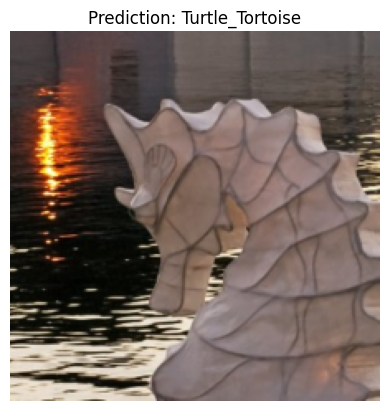

'Turtle_Tortoise'

In [31]:
import random

# Get a list of all images across all subfolders in the dataset
all_images = glob.glob(os.path.join(DATA_PATH, "*", "*"))

# Randomly pick one
sample_image_path = random.choice(all_images)
print(f"Selected random image: {sample_image_path}")

predict_species(sample_image_path)

## 4.9 Summary

In this module, you:

* Audited a real dataset (Sea Animals) for **data quality** issues like class imbalance and corrupted files
* Built an augmentation pipeline with `torchvision.transforms.v2` to increase training data variety
* Trained a CNN on augmented data and compared behavior against an unaugmented baseline
* **Saved** a trained model and its class mapping to disk
* **Loaded** the saved model in a fresh session and ran **inference** on a new image

These are the same steps you'll use in the Module 10 Capstone Assessment — except there, you'll apply **transfer learning** on top of a pre-trained backbone rather than training a CNN fully from scratch.

### Clear the Memory
Before moving on, please execute the following cell to clear up the GPU memory.

In [32]:
# import IPython
# app = IPython.Application.instance()
# app.kernel.do_shutdown(True)

## References

---

